# nb08 — RNA-only and ATAC-only MLP baselines

Train four independent models: **RNA-only and ATAC-only for MCF7**, then **RNA-only and ATAC-only
for T47D**. Predict treatment: **E2 = 1; Vehicle = 0**.
**nb09 will integrate RNA and ATAC using these saved cell splits.**

**Prepared without execution. You will run this notebook in Colab.**
Choose a GPU runtime (e.g. T4), then run all cells. CPU works but is slower.
The implementation is embedded: no source files or repository installation are needed.

Required nb02 files in your Drive project's data/processed/ directory:
- MCF7_RNA_paper_qc.h5ad and MCF7_ATAC_paired_paper_qc.h5ad
- T47D_RNA_paper_qc.h5ad and T47D_ATAC_paired_paper_qc.h5ad

Default project: /content/drive/MyDrive/breast-cancer-multiome-estrogen.
Change BASE below if your folder differs.


## Design fixed before training

- Stratified splits, seed 42: approximately **72% train / 8% validation / 20% test** per cell line.
  Both modalities use identical cell IDs and labels in every split.
- Up to **5,000 variable features selected only on training cells**, detected in at least three
  training cells. No nb03–nb07 DEG, DA, pathways, motifs, PCA or LSI enter prediction.
- RNA: raw counts layer → log1p → training log-space variance selection → training centering/scaling.
  ATAC: raw peak counts → binary (>0) → training binary variance selection; no scaling or TF–IDF.
  Sparse inputs are densified only one minibatch at a time.
- Five 512-unit ReLU hidden layers, dropout 0.1 after each; one output logit.
  Adam learning rate 0.001, binary cross-entropy, batch size 256, maximum 100 epochs.
- Validation-loss early stopping: patience 5, minimum improvement 0.0001.
  Restore selected weights, then evaluate test cells. Threshold fixed at 0.5.
- Main metric **AUROC**; also average precision, accuracy, balanced accuracy, E2 F1/precision/recall,
  log loss, Brier score and confusion counts. A constant training-prevalence dummy baseline is saved.

### Relationship to the paper
Architecture/dropout follow the authors' [MLP implementation](
https://github.com/ohsu-cedar-comp-hub/scMKL_paper/blob/84d68eef6a0985ba757d4b8d4158bc765f48c1ac/Performance_Comparisons/mlp_classification.py)
for [Kupp et al. (2025)](https://doi.org/10.1038/s42003-025-08533-7).
This is a **paper-informed baseline, not an exact reproduction**:
PyTorch replaces Keras; one fixed split/batch size replaces repeated splits and four-fold batch-size
tuning. RNA selection/scaling use consistent log-space training statistics; the paper code uses
raw-count variance/SD. Early-stopping patience and best-weight restoration also differ.

### Interpretation
Available metadata do not identify independent biological replicates; treatment may be confounded
with library effects. These are held-out-cell scores within each cell line, not evidence of patient
or replicate generalization. Inputs inherit nb02 whole-cohort QC/gene filtering; learned model
preprocessing is refitted on training cells only. One split does not estimate split variability.
Keep the test set out of all later tuning; nb09 should select models on validation.


In [2]:
# Keep Colab's GPU-enabled PyTorch; install only missing dependencies.
import importlib.util
import subprocess
import sys
packages = {"anndata":"anndata>=0.11,<0.13","h5py":"h5py","numpy":"numpy",
            "pandas":"pandas","scipy":"scipy","sklearn":"scikit-learn",
            "matplotlib":"matplotlib","torch":"torch"}
missing = [spec for module,spec in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*missing])


In [3]:
from pathlib import Path
from datetime import datetime, timezone
import os
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/breast-cancer-multiome-estrogen")
else:
    current = Path.cwd()
    BASE = Path(os.environ.get("MULTIOME_PROJECT_ROOT",
                str(current.parent if current.name == "notebooks" else current)))
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
required = [BASE/"data"/"processed"/f"{line}_{suffix}.h5ad"
            for line in ("MCF7","T47D")
            for suffix in ("RNA_paper_qc","ATAC_paired_paper_qc")]
missing_files = [str(p) for p in required if not p.is_file()]
if missing_files:
    raise FileNotFoundError("Missing nb02 files:\n"+"\n".join(missing_files))
print("Project:",BASE)
print("Run:",RUN_ID)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/breast-cancer-multiome-estrogen
Run: 20261011T103750_408739Z


## Configuration
Change settings before starting the run; the same settings apply to both modalities.

In [4]:
CONFIG = {'cell_lines': ['MCF7', 'T47D'], 'seed': 42, 'test_fraction': 0.2, 'val_fraction_remaining': 0.1, 'max_features': 5000, 'min_train_detected': 3, 'hidden_sizes': [512, 512, 512, 512, 512], 'dropout': 0.1, 'learning_rate': 0.00001, 'batch_size': 256, 'max_epochs': 100, 'patience': 5, 'min_delta': 0.0001}
CONFIG

{'cell_lines': ['MCF7', 'T47D'],
 'seed': 42,
 'test_fraction': 0.2,
 'val_fraction_remaining': 0.1,
 'max_features': 5000,
 'min_train_detected': 3,
 'hidden_sizes': [512, 512, 512, 512, 512],
 'dropout': 0.1,
 'learning_rate': 1e-05,
 'batch_size': 256,
 'max_epochs': 100,
 'patience': 5,
 'min_delta': 0.0001}

## Embedded implementation
The next cell defines functions only. The following setup cell saves split manifests,
environment versions and fingerprints of the four input files. Hashing can take time on Drive.


In [5]:
"""nb08: separate RNA/ATAC MLPs. Importing defines functions only."""
from pathlib import Path
import gc
import hashlib
import importlib.metadata
import json
import platform
import random
import shutil
import sys
import time
import anndata as ad
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, f1_score, precision_score, recall_score, log_loss,
    brier_score_loss, confusion_matrix, roc_curve, precision_recall_curve)

def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(8*1024*1024), b""):
            h.update(block)
    return h.hexdigest()

def input_path(base, line, modality):
    suffix = "RNA_paper_qc" if modality == "RNA" else "ATAC_paired_paper_qc"
    return Path(base)/"data"/"processed"/f"{line}_{suffix}.h5ad"

def annotations(path):
    with h5py.File(path, "r") as f:
        obs, var = ad.io.read_elem(f["obs"]), ad.io.read_elem(f["var"])
    if not obs.index.is_unique or not var.index.is_unique:
        raise ValueError("Duplicate cell or feature IDs.")
    return obs, var

def prepare(base, config, run_id):
    out = Path(base)/"results"/"tables"/"nb08"/run_id
    models = Path(base)/"data"/"processed"/"nb08"/run_id
    if out.exists() or models.exists():
        raise FileExistsError("Choose a new RUN_ID; this run already exists.")
    out.mkdir(parents=True)
    models.mkdir(parents=True)
    save_json(out/"config.json", config)
    packages = ["anndata","h5py","numpy","pandas","scipy","scikit-learn","matplotlib","torch"]
    save_json(out/"environment.json", {
        "python":sys.version, "platform":platform.platform(),
        "packages":{p:importlib.metadata.version(p) for p in packages},
        "cuda":torch.version.cuda,
        "device":torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"})
    manifests, provenance = {}, []
    for line in config["cell_lines"]:
        paths = [input_path(base,line,m) for m in ("RNA","ATAC")]
        a, _ = annotations(paths[0])
        b, _ = annotations(paths[1])
        labels = a["treatment"].astype(str).to_numpy()
        if not a.index.equals(b.index) or not np.array_equal(labels,b["treatment"].astype(str)):
            raise ValueError(f"{line}: RNA/ATAC cell order or treatment mismatch.")
        if set(labels) != {"E2","Vehicle"}:
            raise ValueError("Unexpected treatment labels.")
        if any(set(o["cell_line"].astype(str)) != {line} for o in (a,b)):
            raise ValueError("Unexpected cell-line labels.")
        y = (labels == "E2").astype(int)
        trainval, test = train_test_split(np.arange(len(y)), test_size=config["test_fraction"],
                                         stratify=y, random_state=config["seed"])
        train, val = train_test_split(trainval, test_size=config["val_fraction_remaining"],
                                     stratify=y[trainval], random_state=config["seed"]+1)
        assert not set(train)&set(val) and not set(train)&set(test) and not set(val)&set(test)
        assert len(train)+len(val)+len(test) == len(y)
        if any(len(np.unique(y[ix])) != 2 for ix in (train,val,test)):
            raise ValueError("Every split must contain both classes.")
        split = np.full(len(y),"",dtype=object)
        split[train],split[val],split[test] = "train","validation","test"
        manifest = pd.DataFrame({"cell_id":a.index.astype(str),"cell_line":line,
            "treatment":labels,"label_E2":y,"split":split})
        manifest.to_csv(out/f"{line}_splits.csv",index=False)
        manifests[line] = manifest
        for modality,path in zip(("RNA","ATAC"),paths):
            print(f"Fingerprinting {line} {modality}...",flush=True)
            provenance.append({"cell_line":line,"modality":modality,
                "path":str(path.relative_to(base)),"bytes":path.stat().st_size,"sha256":sha256(path)})
    pd.DataFrame(provenance).to_csv(out/"input_provenance.csv",index=False)
    counts = pd.concat([m.groupby(["cell_line","split","treatment"]).size().rename("cells").reset_index()
                        for m in manifests.values()],ignore_index=True)
    counts.to_csv(out/"split_counts.csv",index=False)
    save_json(out/"integration_handoff.json",{
        "positive_class":"E2", "run_id":run_id,
        "manifests":{line:{"file":f"{line}_splits.csv","sha256":sha256(out/f"{line}_splits.csv")}
                     for line in config["cell_lines"]},
        "models_directory":str(models.relative_to(base)),
        "instruction":"nb09 must reuse these exact cell splits; fit on train, select on validation, "
                      "evaluate test only after selection."})
    return out,models,manifests,counts

def load_features(base,line,modality,manifest,config):
    path = input_path(base,line,modality)
    obs,var = annotations(path)
    if list(obs.index.astype(str)) != manifest["cell_id"].tolist():
        raise ValueError("Input cell order changed.")
    with h5py.File(path,"r") as f:
        x = ad.io.read_elem(f["layers/counts" if modality == "RNA" else "X"])
    if not sp.issparse(x):
        raise TypeError("Expected sparse raw counts.")
    x = x.tocsr().astype(np.float32)
    x.sum_duplicates()
    x.eliminate_zeros()
    if x.shape != (len(obs),len(var)):
        raise ValueError("Matrix/metadata dimensions differ.")
    if not np.isfinite(x.data).all() or np.any(x.data<0):
        raise ValueError("Invalid counts.")
    if not np.allclose(x.data,np.rint(x.data),atol=1e-5,rtol=0):
        raise ValueError("Expected raw integer counts.")
    if modality == "RNA":
        x.data = np.log1p(x.data)
    else:
        x.data.fill(1)
    train = x[np.flatnonzero(manifest["split"].to_numpy()=="train")].astype(np.float64)
    mean = np.asarray(train.mean(axis=0)).ravel()
    variance = np.maximum(np.asarray(train.power(2).mean(axis=0)).ravel()-mean**2,0)
    detected = np.asarray(train.getnnz(axis=0)).ravel()
    eligible = np.flatnonzero((detected>=config["min_train_detected"]) & (variance>1e-8))
    if not len(eligible):
        raise ValueError("No eligible training features.")
    selected = eligible[np.argsort(-variance[eligible],kind="stable")[:config["max_features"]]]
    center = mean[selected].astype(np.float32) if modality=="RNA" else np.zeros(len(selected),np.float32)
    scale = np.sqrt(variance[selected]).astype(np.float32) if modality=="RNA" else np.ones(len(selected),np.float32)
    table = pd.DataFrame({"input_column":selected,"feature_id":var.index.astype(str).to_numpy()[selected],
        "training_detected_cells":detected[selected],"training_mean":mean[selected],
        "training_variance":variance[selected],"model_center":center,"model_scale":scale})
    return x[:,selected].tocsr(),center,scale,table

def make_model(n_features,config):
    layers=[]
    for width in config["hidden_sizes"]:
        layers.extend([nn.Linear(n_features,width),nn.ReLU(),nn.Dropout(config["dropout"])])
        n_features=width
    return nn.Sequential(*layers,nn.Linear(n_features,1))

def batches(x,y,indices,center,scale,batch_size,device,rng=None):
    order=np.array(indices,copy=True)
    if rng is not None:
        rng.shuffle(order)
    for start in range(0,len(order),batch_size):
        ix=order[start:start+batch_size]
        dense=x[ix].toarray()  # Densify only one minibatch.
        dense-=center
        dense/=scale
        yield torch.from_numpy(dense).to(device),torch.from_numpy(y[ix].astype(np.float32)).to(device)

def evaluate(model,x,y,ix,center,scale,config,device):
    model.eval()
    total,probabilities=0.,[]
    with torch.no_grad():
        for xb,yb in batches(x,y,ix,center,scale,config["batch_size"],device):
            logits=model(xb).ravel()
            total+=nn.functional.binary_cross_entropy_with_logits(logits,yb,reduction="sum").item()
            probabilities.append(torch.sigmoid(logits).cpu().numpy())
    return total/len(ix),np.concatenate(probabilities)

def metrics(y,p):
    pred=(p>=.5).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {"n_cells":len(y),"E2_prevalence":float(y.mean()),
        "AUROC":float(roc_auc_score(y,p)),"average_precision":float(average_precision_score(y,p)),
        "accuracy":float(accuracy_score(y,pred)),"balanced_accuracy":float(balanced_accuracy_score(y,pred)),
        "F1_E2":float(f1_score(y,pred,zero_division=0)),
        "precision_E2":float(precision_score(y,pred,zero_division=0)),
        "recall_E2":float(recall_score(y,pred,zero_division=0)),
        "log_loss":float(log_loss(y,p,labels=[0,1])),"brier_score":float(brier_score_loss(y,p)),
        "TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp)}

def plot_diagnostics(history,y,p,result,path,tag):
    fig,ax=plt.subplots(1,4,figsize=(19,4))
    ax[0].plot(history["epoch"],history["train_loss"],label="Train")
    ax[0].plot(history["epoch"],history["validation_loss"],label="Validation")
    ax[0].set(xlabel="Epoch",ylabel="Binary cross-entropy",title="Learning curves")
    ax[0].legend()
    fpr,tpr,_=roc_curve(y,p)
    ax[1].plot(fpr,tpr,label=f'AUROC={result["AUROC"]:.3f}')
    ax[1].plot([0,1],[0,1],"--",color="grey")
    ax[1].set(xlabel="False positive rate",ylabel="True positive rate",title="Test ROC")
    ax[1].legend()
    precision,recall,_=precision_recall_curve(y,p)
    ax[2].plot(recall,precision,label=f'AP={result["average_precision"]:.3f}')
    ax[2].axhline(y.mean(),linestyle="--",color="grey",label="E2 prevalence")
    ax[2].set(xlabel="Recall",ylabel="Precision",title="Test precision–recall")
    ax[2].legend()
    cm=confusion_matrix(y,p>=.5,labels=[0,1])
    ax[3].imshow(cm,cmap="Blues")
    ax[3].set(xticks=[0,1],yticks=[0,1],xticklabels=["Vehicle","E2"],yticklabels=["Vehicle","E2"],
              xlabel="Predicted",ylabel="Actual",title="Test confusion matrix")
    for row in range(2):
        for col in range(2):
            ax[3].text(col,row,str(cm[row,col]),ha="center",va="center",color="black")
    fig.suptitle(tag)
    fig.tight_layout()
    fig.savefig(path,dpi=160,bbox_inches="tight")
    plt.show()
    plt.close(fig)

def train_one(base,out,models,manifest,line,modality,config):
    tag=f"{line}_{modality}"
    if (out/f"{tag}_metrics.json").exists():
        raise FileExistsError("Model completed already. Use a new RUN_ID to retrain.")
    if config != json.loads((out/"config.json").read_text()):
        raise ValueError("Configuration changed after split creation. Start a new run.")
    random.seed(config["seed"])
    np.random.seed(config["seed"])
    torch.manual_seed(config["seed"])
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(config["seed"])
    torch.backends.cudnn.benchmark=False
    torch.backends.cudnn.deterministic=True
    torch.use_deterministic_algorithms(True,warn_only=True)
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
    x,center,scale,features=load_features(base,line,modality,manifest,config)
    features.to_csv(out/f"{tag}_features.csv",index=False)
    np.savez_compressed(models/f"{tag}_preprocessing.npz",
        input_columns=features["input_column"].to_numpy(),
        feature_ids=features["feature_id"].to_numpy(dtype=str),center=center,scale=scale)
    y=manifest["label_E2"].to_numpy(dtype=int)
    train,val,test=[np.flatnonzero(manifest["split"].to_numpy()==name) for name in ("train","validation","test")]
    model=make_model(x.shape[1],config).to(device)
    optimizer=torch.optim.Adam(model.parameters(),lr=config["learning_rate"])
    rng=np.random.default_rng(config["seed"])
    history,best_state,best_loss,best_epoch,stale=[],None,float("inf"),0,0
    started=time.monotonic()
    print(f"{tag}: {x.shape[1]} features; train/validation/test={len(train)}/{len(val)}/{len(test)}; {device}",flush=True)
    for epoch in range(1,config["max_epochs"]+1):
        model.train()
        total=0.
        for xb,yb in batches(x,y,train,center,scale,config["batch_size"],device,rng):
            optimizer.zero_grad(set_to_none=True)
            loss=nn.functional.binary_cross_entropy_with_logits(model(xb).ravel(),yb)
            if not torch.isfinite(loss):
                raise FloatingPointError("Nonfinite training loss.")
            loss.backward()
            optimizer.step()
            total+=loss.item()*len(yb)
        val_loss,_=evaluate(model,x,y,val,center,scale,config,device)
        if not np.isfinite(val_loss):
            raise FloatingPointError("Nonfinite validation loss.")
        history.append({"epoch":epoch,"train_loss":total/len(train),"validation_loss":val_loss})
        pd.DataFrame(history).to_csv(out/f"{tag}_history.csv",index=False)
        if val_loss<best_loss-config["min_delta"]:
            best_loss,best_epoch,stale=val_loss,epoch,0
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            torch.save(best_state,models/f"{tag}_weights.pt")
        else:
            stale+=1
        print(f"  {epoch:3d}: train={total/len(train):.5f}, validation={val_loss:.5f}",flush=True)
        if stale>=config["patience"]:
            break
    if best_state is None:
        raise RuntimeError("No valid checkpoint.")
    model.load_state_dict(best_state)
    print(f"Restored selected epoch {best_epoch}.",flush=True)
    # No test access during training or checkpoint selection.
    _,pv=evaluate(model,x,y,val,center,scale,config,device)
    _,pt=evaluate(model,x,y,test,center,scale,config,device)
    for name,ix,p in (("validation",val,pv),("test",test,pt)):
        frame=manifest.iloc[ix].copy()
        frame["probability_E2"]=p
        frame["predicted_label_E2"]=(p>=.5).astype(int)
        frame.to_csv(out/f"{tag}_{name}_predictions.csv",index=False)
    result={"cell_line":line,"modality":modality,"seed":config["seed"],
        "n_features":x.shape[1],"n_train":len(train),"n_validation":len(val),
        "best_epoch":best_epoch,"epochs_run":len(history),"best_validation_loss":best_loss,
        "training_seconds":time.monotonic()-started,**metrics(y[test],pt)}
    save_json(out/f"{tag}_validation_metrics.json",metrics(y[val],pv))
    save_json(out/f"{tag}_dummy_metrics.json",metrics(y[test],np.full(len(test),y[train].mean())))
    save_json(models/f"{tag}_model_spec.json",{
        "config":config,"cell_line":line,"modality":modality,"positive_class":"E2",
        "n_features":x.shape[1],"best_epoch":best_epoch,"split_sha256":sha256(out/f"{line}_splits.csv"),
        "transform":"log1p raw counts then train centering/scaling" if modality=="RNA" else "binary counts > 0",
        "weights":f"{tag}_weights.pt","preprocessing":f"{tag}_preprocessing.npz"})
    plot_diagnostics(pd.DataFrame(history),y[test],pt,result,out/f"{tag}_diagnostics.png",tag)
    save_json(out/f"{tag}_metrics.json",result)
    del model,optimizer,x,best_state
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return pd.DataFrame([result])

def summarize(base,out,config):
    paths=[out/f"{line}_{m}_metrics.json" for line in config["cell_lines"] for m in ("RNA","ATAC")]
    missing=[p.name for p in paths if not p.exists()]
    if missing:
        raise RuntimeError(f"Complete all four models first: {missing}")
    summary=pd.DataFrame([json.loads(p.read_text()) for p in paths])
    for line in config["cell_lines"]:
        a,b=[pd.read_csv(out/f"{line}_{m}_test_predictions.csv",dtype={"cell_id":str}) for m in ("RNA","ATAC")]
        if not a[["cell_id","label_E2"]].equals(b[["cell_id","label_E2"]]):
            raise ValueError("RNA/ATAC test predictions are not paired.")
    summary.to_csv(out/"metrics_summary.csv",index=False)
    fig,axes=plt.subplots(1,2,figsize=(10,4))
    for ax,metric in zip(axes,("AUROC","average_precision")):
        summary.pivot(index="cell_line",columns="modality",values=metric).plot.bar(ax=ax)
        ax.set(ylim=(0,1.02),ylabel=metric,xlabel="",title=f"Test {metric}")
        ax.tick_params(axis="x",rotation=0)
    fig.tight_layout()
    fig.savefig(out/"unimodal_comparison.png",dpi=160)
    plt.show()
    plt.close(fig)
    exports=Path(base)/"results"/"exports"
    exports.mkdir(parents=True,exist_ok=True)
    archive=shutil.make_archive(str(exports/f"nb08_{out.name}"),"zip",root_dir=out)
    print("Share results:",archive)
    print("Weights/preprocessing remain in data/processed/nb08 for nb09.")
    return summary,Path(archive)


In [6]:
from IPython.display import display
OUTPUT, MODELS, MANIFESTS, split_counts = prepare(BASE,CONFIG,RUN_ID)
display(split_counts)
print("Results:",OUTPUT)
print("Models:",MODELS)
print("Device:","GPU" if torch.cuda.is_available() else "CPU (slower)")

_ = (OUTPUT/'unimodal_mlp_source.py').write_text('"""nb08: separate RNA/ATAC MLPs. Importing defines functions only."""\nfrom pathlib import Path\nimport gc\nimport hashlib\nimport importlib.metadata\nimport json\nimport platform\nimport random\nimport shutil\nimport sys\nimport time\nimport anndata as ad\nimport h5py\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport scipy.sparse as sp\nimport torch\nfrom torch import nn\nfrom sklearn.model_selection import train_test_split\nfrom sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,\n    balanced_accuracy_score, f1_score, precision_score, recall_score, log_loss,\n    brier_score_loss, confusion_matrix, roc_curve, precision_recall_curve)\n\ndef save_json(path, value):\n    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False) + "\\n")\n\ndef sha256(path):\n    h = hashlib.sha256()\n    with Path(path).open("rb") as f:\n        for block in iter(lambda: f.read(8*1024*1024), b""):\n            h.update(block)\n    return h.hexdigest()\n\ndef input_path(base, line, modality):\n    suffix = "RNA_paper_qc" if modality == "RNA" else "ATAC_paired_paper_qc"\n    return Path(base)/"data"/"processed"/f"{line}_{suffix}.h5ad"\n\ndef annotations(path):\n    with h5py.File(path, "r") as f:\n        obs, var = ad.io.read_elem(f["obs"]), ad.io.read_elem(f["var"])\n    if not obs.index.is_unique or not var.index.is_unique:\n        raise ValueError("Duplicate cell or feature IDs.")\n    return obs, var\n\ndef prepare(base, config, run_id):\n    out = Path(base)/"results"/"tables"/"nb08"/run_id\n    models = Path(base)/"data"/"processed"/"nb08"/run_id\n    if out.exists() or models.exists():\n        raise FileExistsError("Choose a new RUN_ID; this run already exists.")\n    out.mkdir(parents=True)\n    models.mkdir(parents=True)\n    save_json(out/"config.json", config)\n    packages = ["anndata","h5py","numpy","pandas","scipy","scikit-learn","matplotlib","torch"]\n    save_json(out/"environment.json", {\n        "python":sys.version, "platform":platform.platform(),\n        "packages":{p:importlib.metadata.version(p) for p in packages},\n        "cuda":torch.version.cuda,\n        "device":torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"})\n    manifests, provenance = {}, []\n    for line in config["cell_lines"]:\n        paths = [input_path(base,line,m) for m in ("RNA","ATAC")]\n        a, _ = annotations(paths[0])\n        b, _ = annotations(paths[1])\n        labels = a["treatment"].astype(str).to_numpy()\n        if not a.index.equals(b.index) or not np.array_equal(labels,b["treatment"].astype(str)):\n            raise ValueError(f"{line}: RNA/ATAC cell order or treatment mismatch.")\n        if set(labels) != {"E2","Vehicle"}:\n            raise ValueError("Unexpected treatment labels.")\n        if any(set(o["cell_line"].astype(str)) != {line} for o in (a,b)):\n            raise ValueError("Unexpected cell-line labels.")\n        y = (labels == "E2").astype(int)\n        trainval, test = train_test_split(np.arange(len(y)), test_size=config["test_fraction"],\n                                         stratify=y, random_state=config["seed"])\n        train, val = train_test_split(trainval, test_size=config["val_fraction_remaining"],\n                                     stratify=y[trainval], random_state=config["seed"]+1)\n        assert not set(train)&set(val) and not set(train)&set(test) and not set(val)&set(test)\n        assert len(train)+len(val)+len(test) == len(y)\n        if any(len(np.unique(y[ix])) != 2 for ix in (train,val,test)):\n            raise ValueError("Every split must contain both classes.")\n        split = np.full(len(y),"",dtype=object)\n        split[train],split[val],split[test] = "train","validation","test"\n        manifest = pd.DataFrame({"cell_id":a.index.astype(str),"cell_line":line,\n            "treatment":labels,"label_E2":y,"split":split})\n        manifest.to_csv(out/f"{line}_splits.csv",index=False)\n        manifests[line] = manifest\n        for modality,path in zip(("RNA","ATAC"),paths):\n            print(f"Fingerprinting {line} {modality}...",flush=True)\n            provenance.append({"cell_line":line,"modality":modality,\n                "path":str(path.relative_to(base)),"bytes":path.stat().st_size,"sha256":sha256(path)})\n    pd.DataFrame(provenance).to_csv(out/"input_provenance.csv",index=False)\n    counts = pd.concat([m.groupby(["cell_line","split","treatment"]).size().rename("cells").reset_index()\n                        for m in manifests.values()],ignore_index=True)\n    counts.to_csv(out/"split_counts.csv",index=False)\n    save_json(out/"integration_handoff.json",{\n        "positive_class":"E2", "run_id":run_id,\n        "manifests":{line:{"file":f"{line}_splits.csv","sha256":sha256(out/f"{line}_splits.csv")}\n                     for line in config["cell_lines"]},\n        "models_directory":str(models.relative_to(base)),\n        "instruction":"nb09 must reuse these exact cell splits; fit on train, select on validation, "\n                      "evaluate test only after selection."})\n    return out,models,manifests,counts\n\ndef load_features(base,line,modality,manifest,config):\n    path = input_path(base,line,modality)\n    obs,var = annotations(path)\n    if list(obs.index.astype(str)) != manifest["cell_id"].tolist():\n        raise ValueError("Input cell order changed.")\n    with h5py.File(path,"r") as f:\n        x = ad.io.read_elem(f["layers/counts" if modality == "RNA" else "X"])\n    if not sp.issparse(x):\n        raise TypeError("Expected sparse raw counts.")\n    x = x.tocsr().astype(np.float32)\n    x.sum_duplicates()\n    x.eliminate_zeros()\n    if x.shape != (len(obs),len(var)):\n        raise ValueError("Matrix/metadata dimensions differ.")\n    if not np.isfinite(x.data).all() or np.any(x.data<0):\n        raise ValueError("Invalid counts.")\n    if not np.allclose(x.data,np.rint(x.data),atol=1e-5,rtol=0):\n        raise ValueError("Expected raw integer counts.")\n    if modality == "RNA":\n        x.data = np.log1p(x.data)\n    else:\n        x.data.fill(1)\n    train = x[np.flatnonzero(manifest["split"].to_numpy()=="train")].astype(np.float64)\n    mean = np.asarray(train.mean(axis=0)).ravel()\n    variance = np.maximum(np.asarray(train.power(2).mean(axis=0)).ravel()-mean**2,0)\n    detected = np.asarray(train.getnnz(axis=0)).ravel()\n    eligible = np.flatnonzero((detected>=config["min_train_detected"]) & (variance>1e-8))\n    if not len(eligible):\n        raise ValueError("No eligible training features.")\n    selected = eligible[np.argsort(-variance[eligible],kind="stable")[:config["max_features"]]]\n    center = mean[selected].astype(np.float32) if modality=="RNA" else np.zeros(len(selected),np.float32)\n    scale = np.sqrt(variance[selected]).astype(np.float32) if modality=="RNA" else np.ones(len(selected),np.float32)\n    table = pd.DataFrame({"input_column":selected,"feature_id":var.index.astype(str).to_numpy()[selected],\n        "training_detected_cells":detected[selected],"training_mean":mean[selected],\n        "training_variance":variance[selected],"model_center":center,"model_scale":scale})\n    return x[:,selected].tocsr(),center,scale,table\n\ndef make_model(n_features,config):\n    layers=[]\n    for width in config["hidden_sizes"]:\n        layers.extend([nn.Linear(n_features,width),nn.ReLU(),nn.Dropout(config["dropout"])])\n        n_features=width\n    return nn.Sequential(*layers,nn.Linear(n_features,1))\n\ndef batches(x,y,indices,center,scale,batch_size,device,rng=None):\n    order=np.array(indices,copy=True)\n    if rng is not None:\n        rng.shuffle(order)\n    for start in range(0,len(order),batch_size):\n        ix=order[start:start+batch_size]\n        dense=x[ix].toarray()  # Densify only one minibatch.\n        dense-=center\n        dense/=scale\n        yield torch.from_numpy(dense).to(device),torch.from_numpy(y[ix].astype(np.float32)).to(device)\n\ndef evaluate(model,x,y,ix,center,scale,config,device):\n    model.eval()\n    total,probabilities=0.,[]\n    with torch.no_grad():\n        for xb,yb in batches(x,y,ix,center,scale,config["batch_size"],device):\n            logits=model(xb).ravel()\n            total+=nn.functional.binary_cross_entropy_with_logits(logits,yb,reduction="sum").item()\n            probabilities.append(torch.sigmoid(logits).cpu().numpy())\n    return total/len(ix),np.concatenate(probabilities)\n\ndef metrics(y,p):\n    pred=(p>=.5).astype(int)\n    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()\n    return {"n_cells":len(y),"E2_prevalence":float(y.mean()),\n        "AUROC":float(roc_auc_score(y,p)),"average_precision":float(average_precision_score(y,p)),\n        "accuracy":float(accuracy_score(y,pred)),"balanced_accuracy":float(balanced_accuracy_score(y,pred)),\n        "F1_E2":float(f1_score(y,pred,zero_division=0)),\n        "precision_E2":float(precision_score(y,pred,zero_division=0)),\n        "recall_E2":float(recall_score(y,pred,zero_division=0)),\n        "log_loss":float(log_loss(y,p,labels=[0,1])),"brier_score":float(brier_score_loss(y,p)),\n        "TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp)}\n\ndef plot_diagnostics(history,y,p,result,path,tag):\n    fig,ax=plt.subplots(1,4,figsize=(19,4))\n    ax[0].plot(history["epoch"],history["train_loss"],label="Train")\n    ax[0].plot(history["epoch"],history["validation_loss"],label="Validation")\n    ax[0].set(xlabel="Epoch",ylabel="Binary cross-entropy",title="Learning curves")\n    ax[0].legend()\n    fpr,tpr,_=roc_curve(y,p)\n    ax[1].plot(fpr,tpr,label=f\'AUROC={result["AUROC"]:.3f}\')\n    ax[1].plot([0,1],[0,1],"--",color="grey")\n    ax[1].set(xlabel="False positive rate",ylabel="True positive rate",title="Test ROC")\n    ax[1].legend()\n    precision,recall,_=precision_recall_curve(y,p)\n    ax[2].plot(recall,precision,label=f\'AP={result["average_precision"]:.3f}\')\n    ax[2].axhline(y.mean(),linestyle="--",color="grey",label="E2 prevalence")\n    ax[2].set(xlabel="Recall",ylabel="Precision",title="Test precision–recall")\n    ax[2].legend()\n    cm=confusion_matrix(y,p>=.5,labels=[0,1])\n    ax[3].imshow(cm,cmap="Blues")\n    ax[3].set(xticks=[0,1],yticks=[0,1],xticklabels=["Vehicle","E2"],yticklabels=["Vehicle","E2"],\n              xlabel="Predicted",ylabel="Actual",title="Test confusion matrix")\n    for row in range(2):\n        for col in range(2):\n            ax[3].text(col,row,str(cm[row,col]),ha="center",va="center",color="black")\n    fig.suptitle(tag)\n    fig.tight_layout()\n    fig.savefig(path,dpi=160,bbox_inches="tight")\n    plt.show()\n    plt.close(fig)\n\ndef train_one(base,out,models,manifest,line,modality,config):\n    tag=f"{line}_{modality}"\n    if (out/f"{tag}_metrics.json").exists():\n        raise FileExistsError("Model completed already. Use a new RUN_ID to retrain.")\n    if config != json.loads((out/"config.json").read_text()):\n        raise ValueError("Configuration changed after split creation. Start a new run.")\n    random.seed(config["seed"])\n    np.random.seed(config["seed"])\n    torch.manual_seed(config["seed"])\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(config["seed"])\n    torch.backends.cudnn.benchmark=False\n    torch.backends.cudnn.deterministic=True\n    torch.use_deterministic_algorithms(True,warn_only=True)\n    device=torch.device("cuda" if torch.cuda.is_available() else "cpu")\n    x,center,scale,features=load_features(base,line,modality,manifest,config)\n    features.to_csv(out/f"{tag}_features.csv",index=False)\n    np.savez_compressed(models/f"{tag}_preprocessing.npz",\n        input_columns=features["input_column"].to_numpy(),\n        feature_ids=features["feature_id"].to_numpy(dtype=str),center=center,scale=scale)\n    y=manifest["label_E2"].to_numpy(dtype=int)\n    train,val,test=[np.flatnonzero(manifest["split"].to_numpy()==name) for name in ("train","validation","test")]\n    model=make_model(x.shape[1],config).to(device)\n    optimizer=torch.optim.Adam(model.parameters(),lr=config["learning_rate"])\n    rng=np.random.default_rng(config["seed"])\n    history,best_state,best_loss,best_epoch,stale=[],None,float("inf"),0,0\n    started=time.monotonic()\n    print(f"{tag}: {x.shape[1]} features; train/validation/test={len(train)}/{len(val)}/{len(test)}; {device}",flush=True)\n    for epoch in range(1,config["max_epochs"]+1):\n        model.train()\n        total=0.\n        for xb,yb in batches(x,y,train,center,scale,config["batch_size"],device,rng):\n            optimizer.zero_grad(set_to_none=True)\n            loss=nn.functional.binary_cross_entropy_with_logits(model(xb).ravel(),yb)\n            if not torch.isfinite(loss):\n                raise FloatingPointError("Nonfinite training loss.")\n            loss.backward()\n            optimizer.step()\n            total+=loss.item()*len(yb)\n        val_loss,_=evaluate(model,x,y,val,center,scale,config,device)\n        if not np.isfinite(val_loss):\n            raise FloatingPointError("Nonfinite validation loss.")\n        history.append({"epoch":epoch,"train_loss":total/len(train),"validation_loss":val_loss})\n        pd.DataFrame(history).to_csv(out/f"{tag}_history.csv",index=False)\n        if val_loss<best_loss-config["min_delta"]:\n            best_loss,best_epoch,stale=val_loss,epoch,0\n            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}\n            torch.save(best_state,models/f"{tag}_weights.pt")\n        else:\n            stale+=1\n        print(f"  {epoch:3d}: train={total/len(train):.5f}, validation={val_loss:.5f}",flush=True)\n        if stale>=config["patience"]:\n            break\n    if best_state is None:\n        raise RuntimeError("No valid checkpoint.")\n    model.load_state_dict(best_state)\n    print(f"Restored selected epoch {best_epoch}.",flush=True)\n    # No test access during training or checkpoint selection.\n    _,pv=evaluate(model,x,y,val,center,scale,config,device)\n    _,pt=evaluate(model,x,y,test,center,scale,config,device)\n    for name,ix,p in (("validation",val,pv),("test",test,pt)):\n        frame=manifest.iloc[ix].copy()\n        frame["probability_E2"]=p\n        frame["predicted_label_E2"]=(p>=.5).astype(int)\n        frame.to_csv(out/f"{tag}_{name}_predictions.csv",index=False)\n    result={"cell_line":line,"modality":modality,"seed":config["seed"],\n        "n_features":x.shape[1],"n_train":len(train),"n_validation":len(val),\n        "best_epoch":best_epoch,"epochs_run":len(history),"best_validation_loss":best_loss,\n        "training_seconds":time.monotonic()-started,**metrics(y[test],pt)}\n    save_json(out/f"{tag}_validation_metrics.json",metrics(y[val],pv))\n    save_json(out/f"{tag}_dummy_metrics.json",metrics(y[test],np.full(len(test),y[train].mean())))\n    save_json(models/f"{tag}_model_spec.json",{\n        "config":config,"cell_line":line,"modality":modality,"positive_class":"E2",\n        "n_features":x.shape[1],"best_epoch":best_epoch,"split_sha256":sha256(out/f"{line}_splits.csv"),\n        "transform":"log1p raw counts then train centering/scaling" if modality=="RNA" else "binary counts > 0",\n        "weights":f"{tag}_weights.pt","preprocessing":f"{tag}_preprocessing.npz"})\n    plot_diagnostics(pd.DataFrame(history),y[test],pt,result,out/f"{tag}_diagnostics.png",tag)\n    save_json(out/f"{tag}_metrics.json",result)\n    del model,optimizer,x,best_state\n    gc.collect()\n    if torch.cuda.is_available():\n        torch.cuda.empty_cache()\n    return pd.DataFrame([result])\n\ndef summarize(base,out,config):\n    paths=[out/f"{line}_{m}_metrics.json" for line in config["cell_lines"] for m in ("RNA","ATAC")]\n    missing=[p.name for p in paths if not p.exists()]\n    if missing:\n        raise RuntimeError(f"Complete all four models first: {missing}")\n    summary=pd.DataFrame([json.loads(p.read_text()) for p in paths])\n    for line in config["cell_lines"]:\n        a,b=[pd.read_csv(out/f"{line}_{m}_test_predictions.csv",dtype={"cell_id":str}) for m in ("RNA","ATAC")]\n        if not a[["cell_id","label_E2"]].equals(b[["cell_id","label_E2"]]):\n            raise ValueError("RNA/ATAC test predictions are not paired.")\n    summary.to_csv(out/"metrics_summary.csv",index=False)\n    fig,axes=plt.subplots(1,2,figsize=(10,4))\n    for ax,metric in zip(axes,("AUROC","average_precision")):\n        summary.pivot(index="cell_line",columns="modality",values=metric).plot.bar(ax=ax)\n        ax.set(ylim=(0,1.02),ylabel=metric,xlabel="",title=f"Test {metric}")\n        ax.tick_params(axis="x",rotation=0)\n    fig.tight_layout()\n    fig.savefig(out/"unimodal_comparison.png",dpi=160)\n    plt.show()\n    plt.close(fig)\n    exports=Path(base)/"results"/"exports"\n    exports.mkdir(parents=True,exist_ok=True)\n    archive=shutil.make_archive(str(exports/f"nb08_{out.name}"),"zip",root_dir=out)\n    print("Share results:",archive)\n    print("Weights/preprocessing remain in data/processed/nb08 for nb09.")\n    return summary,Path(archive)\n')


Fingerprinting MCF7 RNA...
Fingerprinting MCF7 ATAC...
Fingerprinting T47D RNA...
Fingerprinting T47D ATAC...


,cell_line,split,treatment,cells
0,MCF7,test,E2,658
1,MCF7,test,Vehicle,546
2,MCF7,train,E2,2368
3,MCF7,train,Vehicle,1965
4,MCF7,validation,E2,263
5,MCF7,validation,Vehicle,219
6,T47D,test,E2,713
7,T47D,test,Vehicle,600
8,T47D,train,E2,2567
9,T47D,train,Vehicle,2157


Results: /content/drive/MyDrive/breast-cancer-multiome-estrogen/results/tables/nb08/20261011T103750_408739Z
Models: /content/drive/MyDrive/breast-cancer-multiome-estrogen/data/processed/nb08/20261011T103750_408739Z
Device: GPU


## MCF7 — RNA-only MLP
Run once; the other modality is not an input.

MCF7_RNA: 5000 features; train/validation/test=4333/482/1204; cuda
    1: train=0.69122, validation=0.68978
    2: train=0.68757, validation=0.68517
    3: train=0.68057, validation=0.67574
    4: train=0.66635, validation=0.65773
    5: train=0.64017, validation=0.62681
    6: train=0.59591, validation=0.58099
    7: train=0.53270, validation=0.52366
    8: train=0.45902, validation=0.46000
    9: train=0.38265, validation=0.39180
   10: train=0.30785, validation=0.31874
   11: train=0.23554, validation=0.24400
   12: train=0.17096, validation=0.19094
   13: train=0.12371, validation=0.14294
   14: train=0.08876, validation=0.11258
   15: train=0.06492, validation=0.09132
   16: train=0.04966, validation=0.07982
   17: train=0.03780, validation=0.07113
   18: train=0.02870, validation=0.06493
   19: train=0.02365, validation=0.05997
   20: train=0.01887, validation=0.07033
   21: train=0.01500, validation=0.05579
   22: train=0.01295, validation=0.05852
   23: train=0.00944, validatio

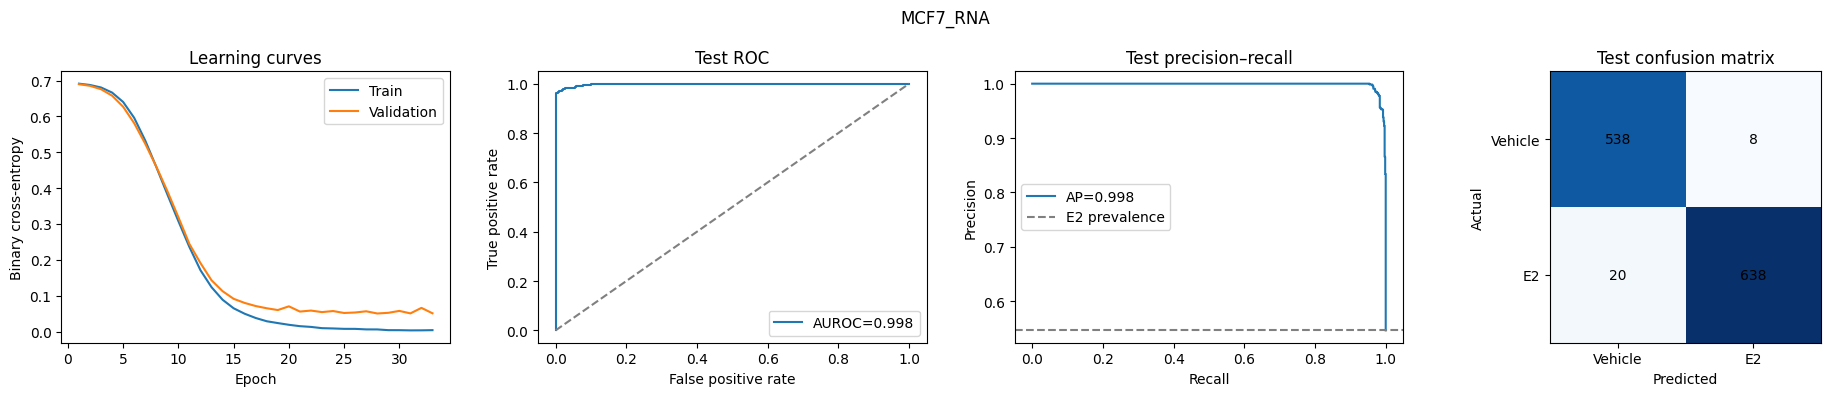

,cell_line,modality,seed,n_features,n_train,n_validation,best_epoch,epochs_run,best_validation_loss,training_seconds,...,balanced_accuracy,F1_E2,precision_E2,recall_E2,log_loss,brier_score,TN,FP,FN,TP
0,MCF7,RNA,42,5000,4333,482,28,33,0.050406,6.090752,...,0.977476,0.978528,0.987616,0.969605,0.059447,0.016871,538,8,20,638


In [7]:
display(train_one(BASE,OUTPUT,MODELS,MANIFESTS["MCF7"],
                  "MCF7","RNA",CONFIG))

## MCF7 — ATAC-only MLP
Run once; the other modality is not an input.

MCF7_ATAC: 5000 features; train/validation/test=4333/482/1204; cuda
    1: train=0.69249, validation=0.69221
    2: train=0.69185, validation=0.69163
    3: train=0.69124, validation=0.69107
    4: train=0.69047, validation=0.69054
    5: train=0.68986, validation=0.68995
    6: train=0.68883, validation=0.68922
    7: train=0.68756, validation=0.68820
    8: train=0.68545, validation=0.68656
    9: train=0.68260, validation=0.68422
   10: train=0.67745, validation=0.67953
   11: train=0.66799, validation=0.67189
   12: train=0.65200, validation=0.65755
   13: train=0.62646, validation=0.63529
   14: train=0.58583, validation=0.60369
   15: train=0.53098, validation=0.56979
   16: train=0.46690, validation=0.52815
   17: train=0.40326, validation=0.49417
   18: train=0.34450, validation=0.46992
   19: train=0.30335, validation=0.45979
   20: train=0.26653, validation=0.45030
   21: train=0.23524, validation=0.45019
   22: train=0.22030, validation=0.47322
   23: train=0.19086, validati

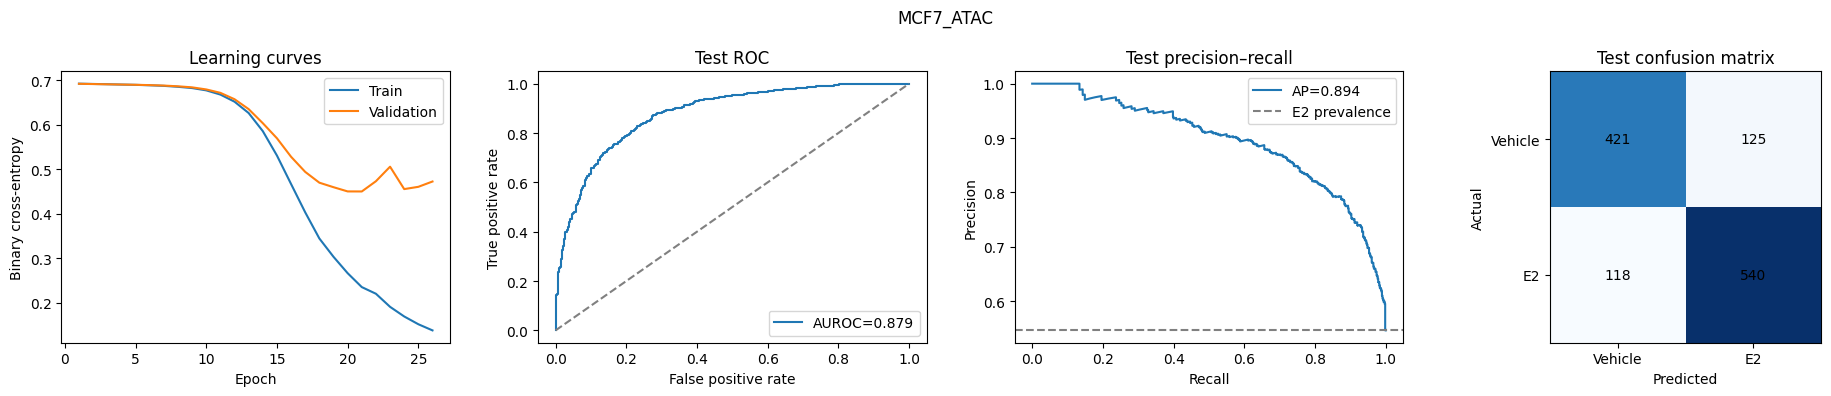

,cell_line,modality,seed,n_features,n_train,n_validation,best_epoch,epochs_run,best_validation_loss,training_seconds,...,balanced_accuracy,F1_E2,precision_E2,recall_E2,log_loss,brier_score,TN,FP,FN,TP
0,MCF7,ATAC,42,5000,4333,482,21,26,0.450185,4.428164,...,0.795865,0.816327,0.81203,0.820669,0.435746,0.140379,421,125,118,540


In [8]:
display(train_one(BASE,OUTPUT,MODELS,MANIFESTS["MCF7"],
                  "MCF7","ATAC",CONFIG))

## T47D — RNA-only MLP
Run once; the other modality is not an input.

T47D_RNA: 5000 features; train/validation/test=4724/525/1313; cuda
    1: train=0.69166, validation=0.69032
    2: train=0.68895, validation=0.68666
    3: train=0.68393, validation=0.67891
    4: train=0.67287, validation=0.66212
    5: train=0.65057, validation=0.62919
    6: train=0.60777, validation=0.57136
    7: train=0.53838, validation=0.48432
    8: train=0.44347, validation=0.38193
    9: train=0.34033, validation=0.28920
   10: train=0.25065, validation=0.21001
   11: train=0.17817, validation=0.15166
   12: train=0.12668, validation=0.11135
   13: train=0.08994, validation=0.08684
   14: train=0.06872, validation=0.06883
   15: train=0.05281, validation=0.06169
   16: train=0.03899, validation=0.04984
   17: train=0.03061, validation=0.04777
   18: train=0.02279, validation=0.04757
   19: train=0.02129, validation=0.04394
   20: train=0.01803, validation=0.03494
   21: train=0.01499, validation=0.03226
   22: train=0.01303, validation=0.03147
   23: train=0.01051, validatio

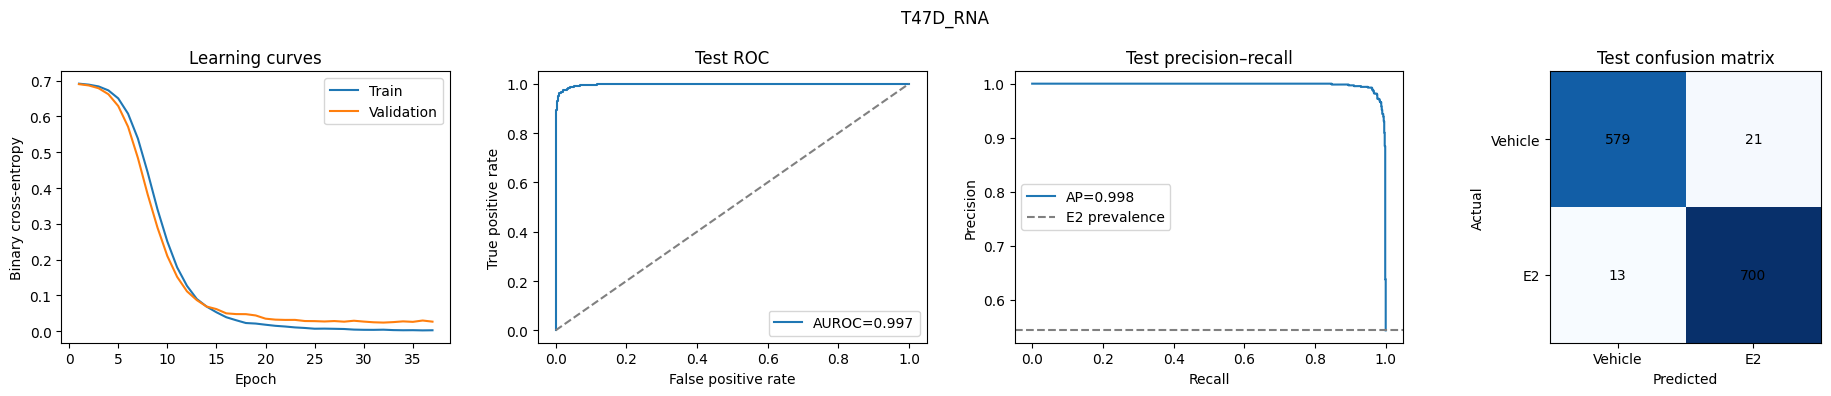

,cell_line,modality,seed,n_features,n_train,n_validation,best_epoch,epochs_run,best_validation_loss,training_seconds,...,balanced_accuracy,F1_E2,precision_E2,recall_E2,log_loss,brier_score,TN,FP,FN,TP
0,T47D,RNA,42,5000,4724,525,32,37,0.024009,7.383522,...,0.973384,0.97629,0.970874,0.981767,0.072442,0.019764,579,21,13,700


In [9]:
display(train_one(BASE,OUTPUT,MODELS,MANIFESTS["T47D"],
                  "T47D","RNA",CONFIG))

## T47D — ATAC-only MLP
Run once; the other modality is not an input.

T47D_ATAC: 5000 features; train/validation/test=4724/525/1313; cuda
    1: train=0.69244, validation=0.69230
    2: train=0.69190, validation=0.69171
    3: train=0.69136, validation=0.69128
    4: train=0.69077, validation=0.69073
    5: train=0.69018, validation=0.69017
    6: train=0.68929, validation=0.68960
    7: train=0.68818, validation=0.68867
    8: train=0.68637, validation=0.68713
    9: train=0.68337, validation=0.68510
   10: train=0.67734, validation=0.68044
   11: train=0.66803, validation=0.67185
   12: train=0.65124, validation=0.65792
   13: train=0.62268, validation=0.64109
   14: train=0.58223, validation=0.60896
   15: train=0.53295, validation=0.57831
   16: train=0.47386, validation=0.54999
   17: train=0.41826, validation=0.52776
   18: train=0.37048, validation=0.53553
   19: train=0.32887, validation=0.50049
   20: train=0.30112, validation=0.50698
   21: train=0.26994, validation=0.50098
   22: train=0.25157, validation=0.50663
   23: train=0.22991, validati

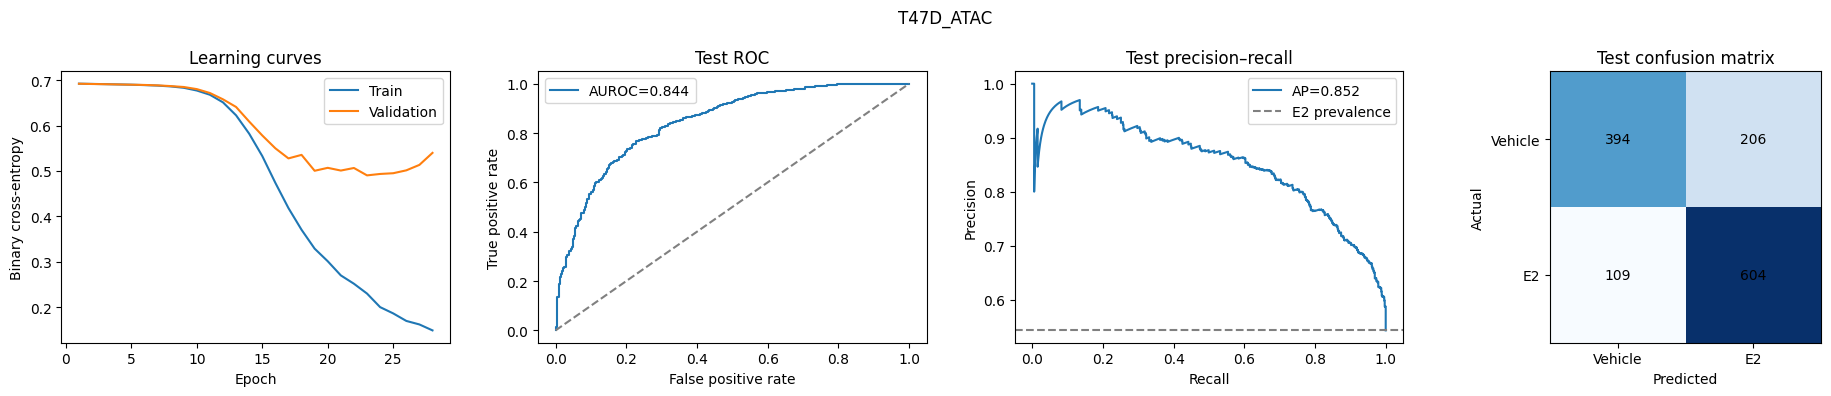

,cell_line,modality,seed,n_features,n_train,n_validation,best_epoch,epochs_run,best_validation_loss,training_seconds,...,balanced_accuracy,F1_E2,precision_E2,recall_E2,log_loss,brier_score,TN,FP,FN,TP
0,T47D,ATAC,42,5000,4724,525,23,28,0.490344,5.163505,...,0.751896,0.793171,0.745679,0.847125,0.504845,0.163584,394,206,109,604


In [10]:
display(train_one(BASE,OUTPUT,MODELS,MANIFESTS["T47D"],
                  "T47D","ATAC",CONFIG))

## Compare and export all four models
The export requires all four training cells to finish and checks that test cells/labels are paired.

The ZIP contains metrics, settings, versions, source, input hashes, split manifests, selected
features, validation/test predictions, histories and diagnostic plots.
Weights and preprocessing arrays remain under data/processed/nb08/RUN_ID/.

**Send back the results ZIP**, or metrics_summary.csv and the diagnostic figures.
Preserve this run for nb09, which must reuse its exact split manifests.


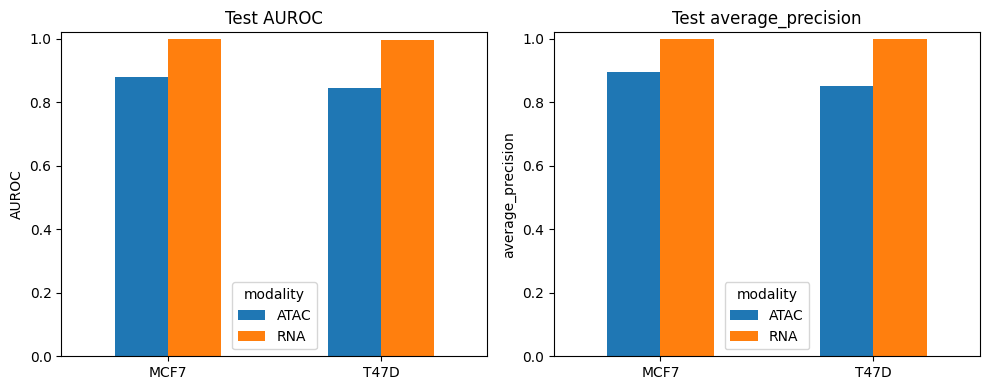

Share results: /content/drive/MyDrive/breast-cancer-multiome-estrogen/results/exports/nb08_20261011T103750_408739Z.zip
Weights/preprocessing remain in data/processed/nb08 for nb09.


,cell_line,modality,n_features,best_epoch,AUROC,average_precision,balanced_accuracy,F1_E2,log_loss
0,MCF7,RNA,5000,28,0.998052,0.998500,0.977476,0.978528,0.059447
1,MCF7,ATAC,5000,21,0.878609,0.894355,0.795865,0.816327,0.435746
2,T47D,RNA,5000,32,0.996933,0.997737,0.973384,0.976290,0.072442
3,T47D,ATAC,5000,23,0.843777,0.852236,0.751896,0.793171,0.504845


Share this archive: /content/drive/MyDrive/breast-cancer-multiome-estrogen/results/exports/nb08_20261011T103750_408739Z.zip


In [11]:
summary, RESULTS_ZIP = summarize(BASE,OUTPUT,CONFIG)
display(summary[["cell_line","modality","n_features","best_epoch","AUROC",
                 "average_precision","balanced_accuracy","F1_E2","log_loss"]])
print("Share this archive:",RESULTS_ZIP)


### Optional download
The ZIP is already saved in Drive. Set DOWNLOAD_RESULTS to True to download through Colab.
Completed models cannot be overwritten in the same run. Changed settings need a new RUN_ID;
report reruns separately. Interrupted training epochs are not resumed automatically.


In [12]:
DOWNLOAD_RESULTS = False
if DOWNLOAD_RESULTS and IN_COLAB:
    from google.colab import files
    files.download(str(RESULTS_ZIP))
